In [1]:
import tensorflow as tf; print('TensorFlow:', tf.__version__); print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: []


## 1.2 Dataset audit

Scan every file for image metadata and a SHA-256 content hash. Display class counts, size statistics, unreadable files and exact duplicates below; no CSV files are written.


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
from IPython.display import display

# The notebook runs from the project directory.
dataset_root = (Path.cwd() / "cashbowman" / "ai-generated-images-vs-real-images"
                / "versions" / "1")
class_folders = {"AI-generated": "AiArtData", "Real": "RealArt"}

def sha256_file(path):
    """Hash file contents in chunks, so large files do not fill memory."""
    digest = hashlib.sha256()
    with path.open("rb") as image_file:
        for chunk in iter(lambda: image_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def inspect_file(path, dataset_root, label):
    record = {
        "path": path.relative_to(dataset_root).as_posix(),
        "class": label,
        "file_size_bytes": "",
        "width": "",
        "height": "",
        "colour_mode": "",
        "format": "",
        "sha256": "",
        "unreadable": False,
        "error": "",
        "duplicate_of": "",
    }
    try:
        record["file_size_bytes"] = path.stat().st_size
        record["sha256"] = sha256_file(path)
        # verify() checks file integrity; load() also checks pixel decoding.
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            record.update(
                width=image.width,
                height=image.height,
                colour_mode=image.mode,
                format=image.format,
            )
    except Exception as error:
        # Keep the failed file in the audit instead of silently skipping it.
        record["unreadable"] = True
        record["error"] = f"{type(error).__name__}: {error}"
    return record

In [3]:
# Scan recursively because the class folder names are repeated inside the download.
records = []
first_seen = {}
for label, folder in class_folders.items():
    class_root = dataset_root / folder
    if not class_root.is_dir():
        raise FileNotFoundError(f"Missing dataset folder: {class_root}")
    paths = sorted(path for path in class_root.rglob("*") if path.is_file())
    if not paths:
        raise ValueError(f"No files found in {class_root}")
    for path in paths:
        row = inspect_file(path, dataset_root, label)
        content_hash = row["sha256"]
        if content_hash:
            if content_hash in first_seen:
                row["duplicate_of"] = first_seen[content_hash]
            else:
                first_seen[content_hash] = row["path"]
        records.append(row)

audit_df = pd.DataFrame(records)
for column in ["width", "height", "file_size_bytes"]:
    audit_df[column] = pd.to_numeric(audit_df[column], errors="coerce").astype("Int64")
print(f"Audited {len(audit_df)} files. The full per-image table is stored in audit_df.")
display(audit_df)


Audited 975 files. The full per-image table is stored in audit_df.


,path,class,file_size_bytes,width,height,colour_mode,format,sha256,unreadable,error,duplicate_of
0,AiArtData/AiArtData/-how-important-people-from...,AI-generated,97136,880,440,RGB,JPEG,410f52ab558884eba3b6b271b4f5ade076f6dc06adbf14...,False,,
1,AiArtData/AiArtData/-s-fluffy-fur-and-round-fe...,AI-generated,329446,2940,1960,RGB,JPEG,e31692a1b6ac7ff0754ea8717ad51e1cbed6267982bace...,False,,
2,AiArtData/AiArtData/-using-generative-ai-techn...,AI-generated,267045,1067,1690,RGB,JPEG,e90cbc6e6199b9f622295d61ef0913f2f64f0544c2f650...,False,,
3,AiArtData/AiArtData/-yellow-kimono-with-a-gold...,AI-generated,89671,800,800,RGB,JPEG,ea4b6260faac11d4914e56c123d87b97c692ab2c3802fa...,False,,
4,AiArtData/AiArtData/.amazonaws.com2Fpublic2Fim...,AI-generated,52677,600,480,RGB,JPEG,3009ba845a440f74016286b0603c244c681a93e1f4a14f...,False,,
...,...,...,...,...,...,...,...,...,...,...,...
970,RealArt/RealArt/Women-clothing-Kenya-East-Afri...,Real,267179,1600,836,RGB,JPEG,e1e3f9dca6ace7a72f6ade3e73c9c76c7adde58a11707e...,False,,
971,RealArt/RealArt/Worlds-15-Most-Iconic-Portrait...,Real,70700,552,800,RGB,JPEG,893f967dc76df6678f85027dc636941ffb41dae9bdd0d1...,False,,
972,RealArt/RealArt/WR202206_GiraffeTranslocation_...,Real,390161,1200,630,RGB,JPEG,99e573355842fdd6919b832593f7e9429ca98ec13bc313...,False,,
973,RealArt/RealArt/XaHpf_z51huQS_JPHs-jkPhBp0dLlx...,Real,636250,2048,1365,RGB,JPEG,c1ee99f18fe1b880896cacaaf1e15e01085aec08fe1b06...,False,,


In [4]:
# Counts and quality checks for each class.
counts = audit_df.groupby("class").agg(
    files=("path", "size"),
    readable_images=("unreadable", lambda values: (~values).sum()),
    corrupt_or_unreadable=("unreadable", "sum"),
    duplicate_files=("duplicate_of", lambda values: values.ne("").sum()),
)
print("Counts per class (duplicates count additional copies beyond the first):")
display(counts)

# Missing dimensions from unreadable files are excluded automatically.
# File-size statistics include every file whose size could be read.
size_stats = audit_df.groupby("class")[["width", "height", "file_size_bytes"]].agg(
    ["min", "median", "max"]
)
print("Image dimensions in pixels and file sizes in bytes:")
display(size_stats)

unreadable_files = audit_df.loc[audit_df["unreadable"], ["path", "class", "error"]]
print(f"Corrupt or unreadable files: {len(unreadable_files)}")
display(unreadable_files)

# Show both the original and every extra copy in each duplicate group.
duplicate_images = audit_df.loc[
    audit_df["sha256"].ne("") & audit_df["sha256"].duplicated(keep=False),
    ["path", "class", "sha256", "duplicate_of"],
].sort_values("sha256")
print(f"Exact duplicate groups: {duplicate_images['sha256'].nunique()}")
print(f"Additional duplicate files: {audit_df['duplicate_of'].ne('').sum()}")
with pd.option_context("display.max_colwidth", None):
    display(duplicate_images)
print("SHA-256 detects identical file bytes; visually similar images may have different hashes.")


Counts per class (duplicates count additional copies beyond the first):


,files,readable_images,corrupt_or_unreadable,duplicate_files
class,,,,
AI-generated,539,539,0,1
Real,436,436,0,0


Image dimensions in pixels and file sizes in bytes:


width               height              file_size_bytes  \
               min  median   max    min median   max             min   
class                                                                  
AI-generated   225  1024.0  6000    135  800.0  4001           11738   
Real           183   920.0  8495    158  720.0  7091           11311   

                                  
                median       max  
class                             
AI-generated  199760.0   5626183  
Real          144840.0  10195352

Corrupt or unreadable files: 0


,path,class,error


Exact duplicate groups: 1
Additional duplicate files: 1


,path,class,sha256,duplicate_of
346,AiArtData/AiArtData/image33.jpg,AI-generated,f3268a4fc0477b2f3d9728f118afe32bf5196c3b476def53e34229672f77dc97,
347,AiArtData/AiArtData/image34.jpg,AI-generated,f3268a4fc0477b2f3d9728f118afe32bf5196c3b476def53e34229672f77dc97,AiArtData/AiArtData/image33.jpg


SHA-256 detects identical file bytes; visually similar images may have different hashes.


## 1.3 Visual EDA

The following figures use the readable images audited in Task 1.2. Histograms include all readable files, including the exact duplicate; only the sample grid excludes repeated hashes.


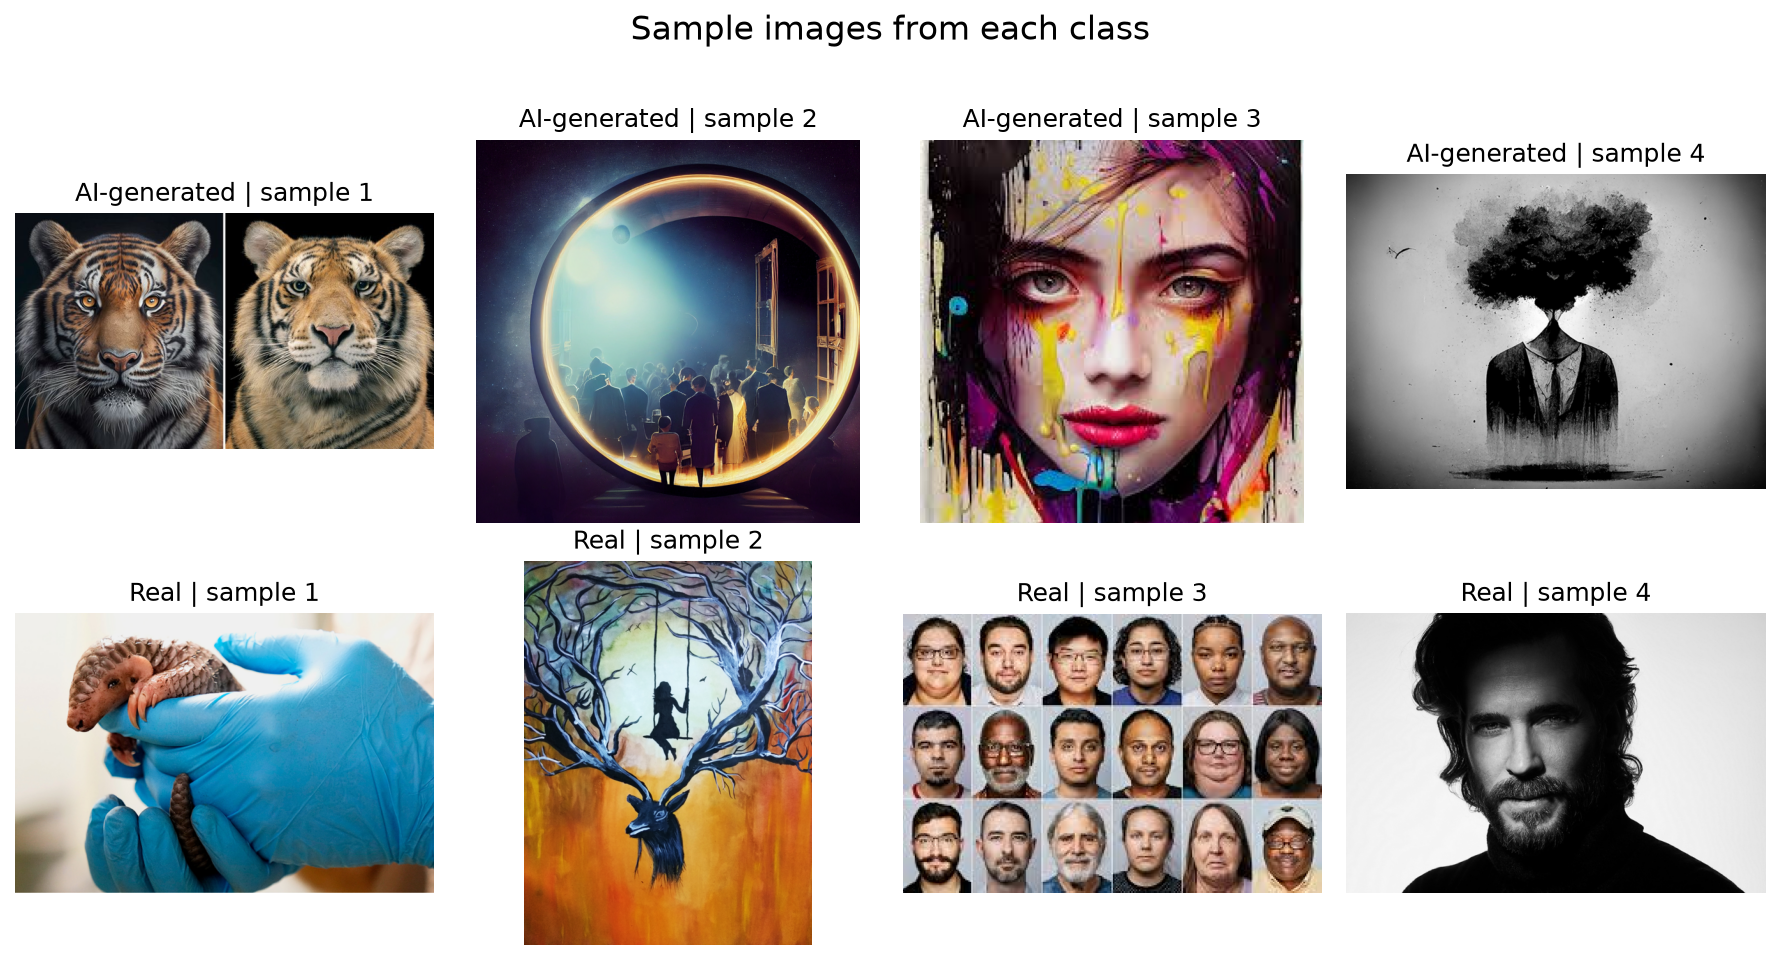

In [5]:
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import ImageOps
from IPython.display import Image as NotebookImage

# Reuse the full image audit from Task 1.2; do not modify the dataset.
eda_df = audit_df.loc[~audit_df["unreadable"]].copy()
class_labels = list(class_folders)
colours = {"AI-generated": "#3769A8", "Real": "#C47830"}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12})

def show_figure(fig):
    # Embed the PNG in the notebook without creating output folders.
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

# A fixed seed makes the sample grid reproducible. Use distinct file hashes here.
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for row_index, label in enumerate(class_labels):
    candidates = eda_df.loc[eda_df["class"] == label].drop_duplicates("sha256")
    samples = candidates.sample(n=min(4, len(candidates)), random_state=42)
    for column_index, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row_index, column_index]
        with Image.open(dataset_root / sample["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.thumbnail((600, 600))
            ax.imshow(image)
        ax.set_title(f"{label} | sample {column_index + 1}")
        ax.axis("off")
    for ax in axes[row_index, len(samples):]:
        ax.axis("off")
fig.suptitle("Sample images from each class", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
show_figure(fig)


**Figure 1. Sample grid with four images from each class, selected using random seed 42 and displayed without stretching.**

The AI-generated samples include animals, a stylized portrait and surreal scenes, while the Real samples include photographs, a painted scene and a collage. The painted image in the Real class shows that artistic style alone does not determine the folder label. These eight examples illustrate variation but are too few to establish the quality of all labels.


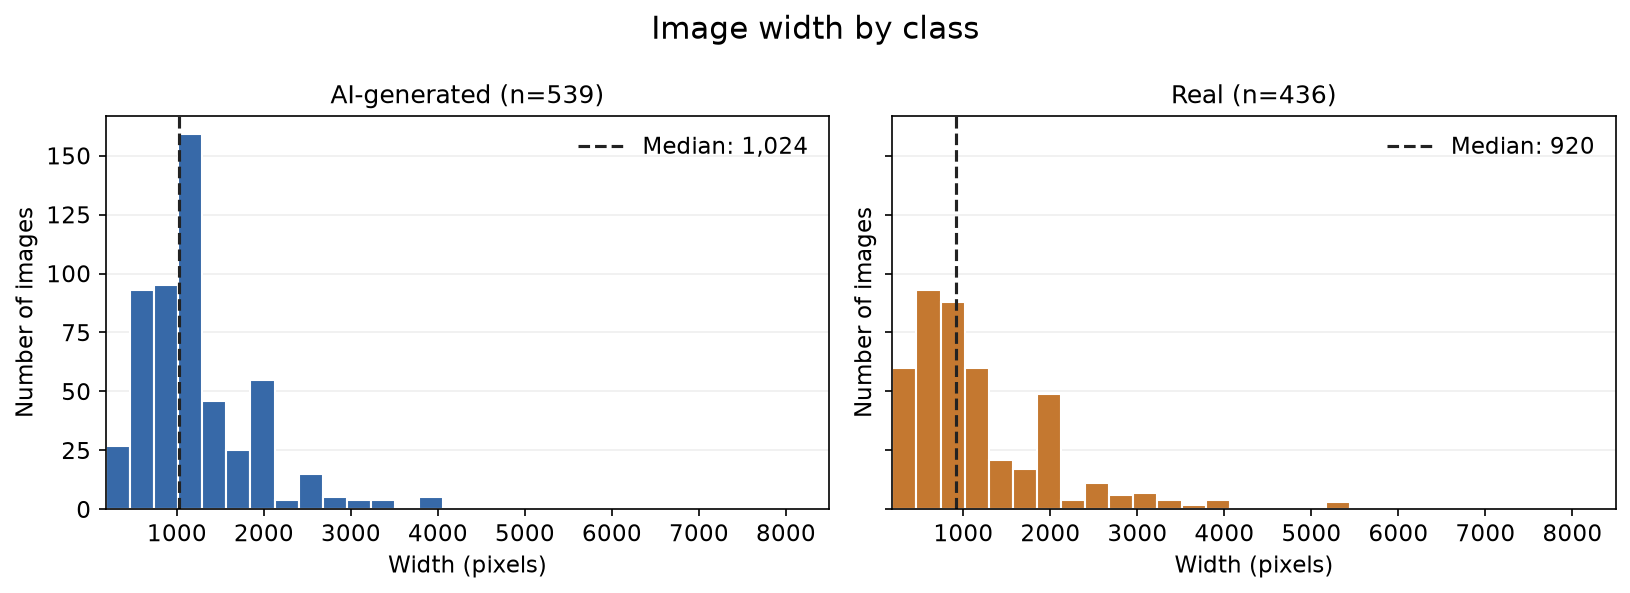

In [6]:
def plot_class_histograms(column, title, x_label, scale=1):
    # Both classes use identical bin edges and axis limits for comparison.
    all_values = eda_df[column].dropna().to_numpy(dtype=float) / scale
    bin_edges = np.histogram_bin_edges(all_values, bins=30)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for ax, label in zip(axes, class_labels):
        values = eda_df.loc[eda_df["class"] == label, column].dropna().to_numpy(dtype=float) / scale
        median = np.median(values)
        ax.hist(values, bins=bin_edges, color=colours[label], edgecolor="white")
        ax.axvline(median, color="#222222", linestyle="--", linewidth=1.5,
                   label=f"Median: {median:,.2f}" if scale != 1 else f"Median: {median:,.0f}")
        ax.set_title(f"{label} (n={len(values)})")
        ax.set_xlabel(x_label)
        ax.set_ylabel("Number of images")
        ax.set_xlim(bin_edges[0], bin_edges[-1])
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(frameon=False)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    show_figure(fig)

plot_class_histograms("width", "Image width by class", "Width (pixels)")


**Figure 2. Width histograms per class, using 30 shared bins and matching axes; dashed lines mark the medians.**

Both width distributions are right-skewed, with many smaller images and a few very wide images. The AI-generated class has a median width of 1,024 pixels compared with 920 pixels for Real, so inputs need a consistent target size before batching.


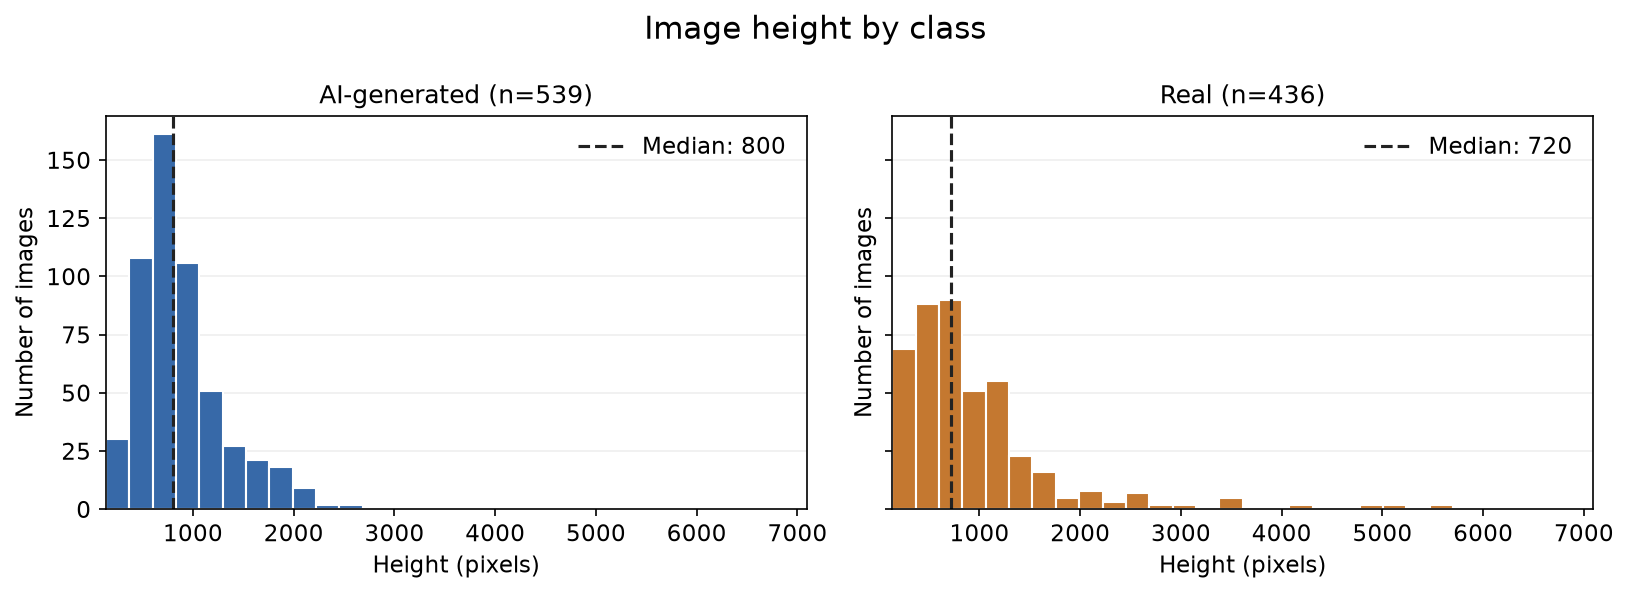

In [7]:
plot_class_histograms("height", "Image height by class", "Height (pixels)")


**Figure 3. Height histograms per class, using 30 shared bins and matching axes; dashed lines mark the medians.**

Image heights also have long right tails, especially in the Real class. Median heights are 800 pixels for AI-generated and 720 pixels for Real, and the variation in both dimensions means resizing should handle aspect ratio explicitly.


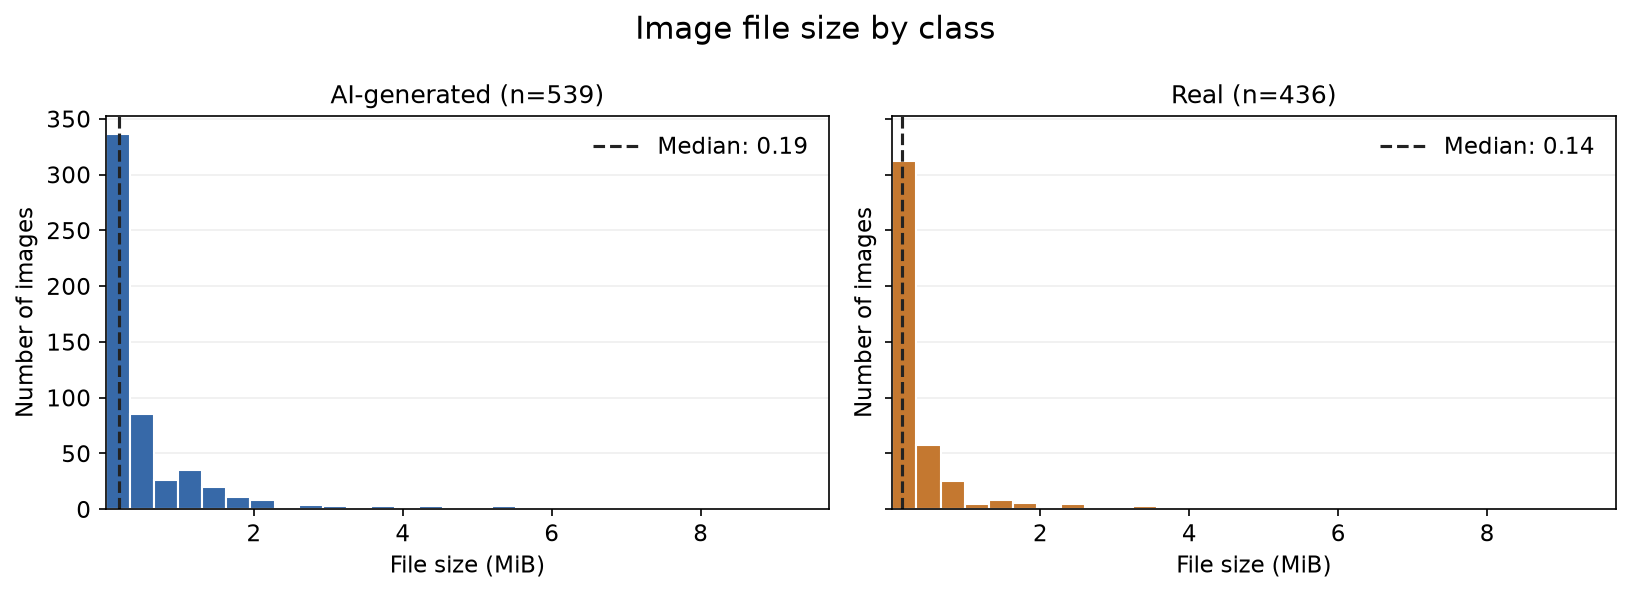

In [8]:
plot_class_histograms("file_size_bytes", "Image file size by class", "File size (MiB)", scale=1024 ** 2)


**Figure 4. File-size histograms per class in MiB, using 30 shared bins and matching axes; dashed lines mark the medians.**

Both classes have strongly right-skewed file-size distributions, with medians of about 0.19 MiB for AI-generated and 0.14 MiB for Real. A few large files extend the tails, so median size describes a typical file better than the maximum; file size alone does not prove whether an image is AI-generated.


## 2.1 Input pipeline

I use a reproducible, stratified 70/15/15 train/validation/test split after excluding unreadable files and removing exact duplicate hashes. The split lists retain relative paths, class labels and SHA-256 hashes, and are saved in `splits/` so later experiments use the same images; overlapping hashes are explicitly rejected.

Images are decoded with Pillow inside `tf.numpy_function` to support this dataset's JPEG, PNG, WebP and GIF files, normalized to RGB, and resized with `tf.image.resize_with_pad` to 128 x 128 pixels. Padding preserves aspect ratio instead of stretching: empty space becomes black borders, while 128 pixels keeps CPU training practical at the cost of some fine detail. Only the first frame of animated files is used, and EXIF orientation is applied consistently.

The pipeline reads each split CSV, decodes/resizes in parallel, caches the resized images in memory, shuffles only training data, batches 16 images, applies random flip/rotation/zoom/contrast only to training batches, and prefetches the next batch. Caching occurs before augmentation, so fresh training transformations remain possible each epoch; validation and test preprocessing is deterministic. Models receive float pixels in [0,255] and contain their own normalization layer.


class,AI-generated,Real
split,,
test,81,66
train,376,305
validation,81,65


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


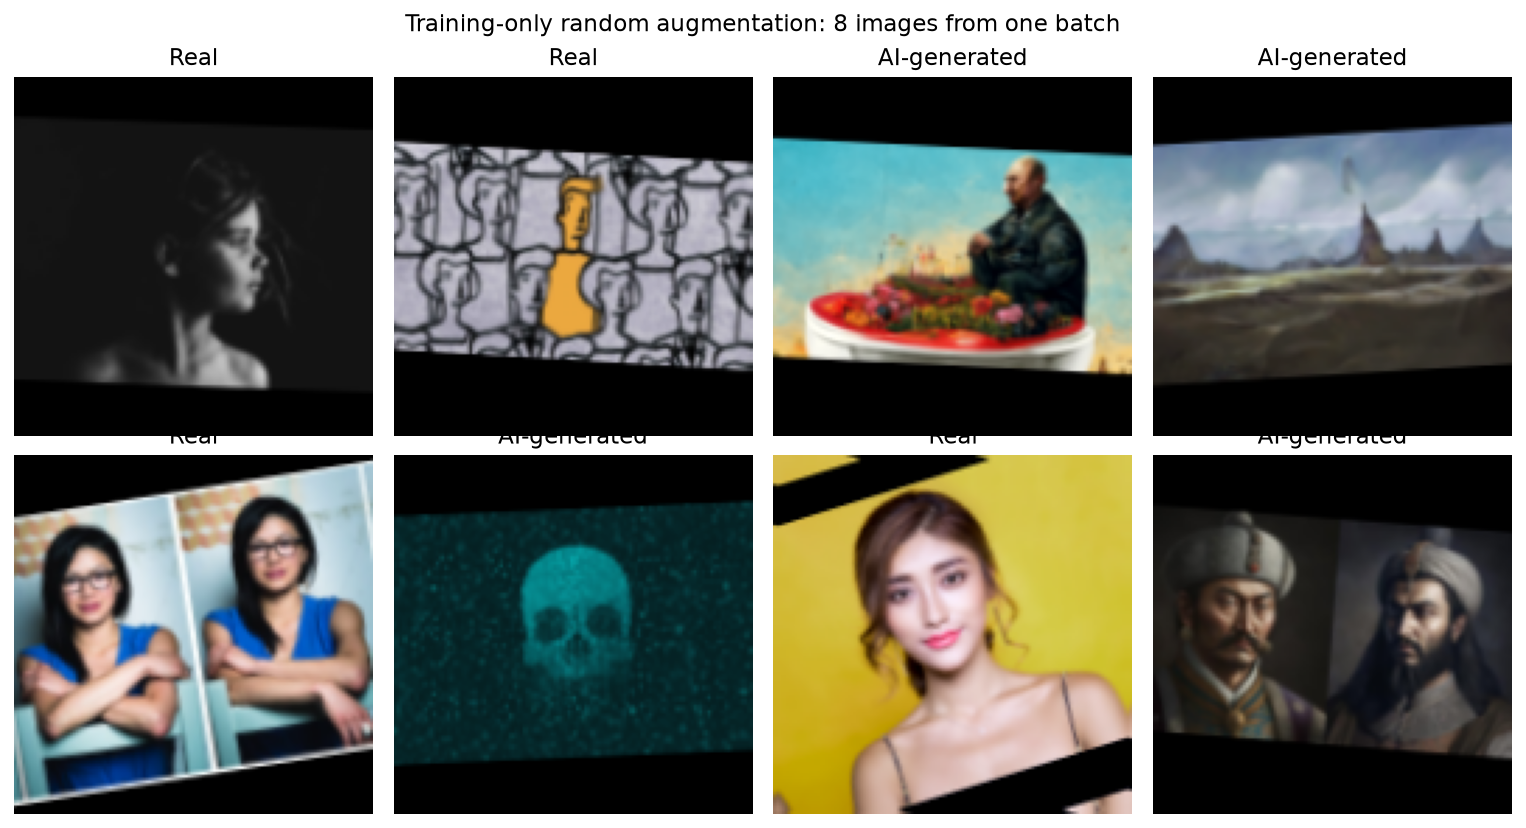

Batch shape: (16, 128, 128, 3) dtype: <dtype: 'float32'>
Positive class: AI-generated (1); negative class: Real (0).


In [9]:
import os
os.environ.setdefault("KERAS_HOME", str(Path.cwd() / "artifacts" / "keras_cache"))
import io
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import ImageOps
from IPython.display import Image as NotebookImage

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Limit parallel CPU work so the desktop remains usable.
try:
    tf.config.threading.set_intra_op_parallelism_threads(8)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass  # An already-running notebook kernel may have initialized TensorFlow.

usable = audit_df.loc[~audit_df["unreadable"]].copy()
if usable.groupby("sha256")["class"].nunique().gt(1).any():
    raise ValueError("Identical files have conflicting class labels; resolve before splitting.")
usable = usable.drop_duplicates("sha256").reset_index(drop=True)
usable["label"] = usable["class"].map({"Real": 0, "AI-generated": 1})
train_rows, heldout_rows = train_test_split(
    usable, test_size=0.30, random_state=SEED, stratify=usable["label"]
)
val_rows, test_rows = train_test_split(
    heldout_rows, test_size=0.50, random_state=SEED, stratify=heldout_rows["label"]
)
split_frames = {"train": train_rows, "validation": val_rows, "test": test_rows}
Path("splits").mkdir(exist_ok=True)
for name, frame in split_frames.items():
    frame[["path", "class", "label", "sha256"]].to_csv(f"splits/{name}.csv", index=False)
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert set(split_frames[left]["sha256"]).isdisjoint(split_frames[right]["sha256"])
display(pd.crosstab(
    pd.concat([frame.assign(split=name) for name, frame in split_frames.items()])["split"],
    pd.concat([frame.assign(split=name) for name, frame in split_frames.items()])["class"],
))

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED + 1),
    layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED + 2),
    layers.RandomContrast(0.10, seed=SEED + 3),
], name="training_augmentation")

def pillow_decode(path_bytes):
    path = path_bytes.decode("utf-8")
    with Image.open(path) as image:
        image.seek(0)
        return np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.uint8)

def decode_resize(path, label):
    image = tf.numpy_function(pillow_decode, [path], tf.uint8)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, *IMAGE_SIZE, antialias=True)
    return image, tf.cast(label, tf.float32)

def make_dataset(split_name, training=False, augment=True):
    frame = pd.read_csv(f"splits/{split_name}.csv")
    paths = [str(dataset_root / path) for path in frame["path"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, frame["label"].to_numpy()))
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 4
    ds = ds.with_options(options).map(decode_resize, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training and augment:
        ds = ds.map(lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0, 255), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset("train", training=True)
val_ds = make_dataset("validation")
test_ds = make_dataset("test")  # Kept untouched until the one-time evaluation in 2.5.

def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

batch_images, batch_labels = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(batch_images[index].numpy().astype("uint8"))
    ax.set_title("AI-generated" if int(batch_labels[index]) else "Real")
    ax.axis("off")
fig.suptitle("Training-only random augmentation: 8 images from one batch")
fig.tight_layout()
show_figure(fig)
print("Batch shape:", batch_images.shape, "dtype:", batch_images.dtype)
print("Positive class: AI-generated (1); negative class: Real (0).")


**Figure 5. Eight examples from one augmented training batch (seed 42).**

The batch contains RGB images with a common 128 x 128 shape, while padding preserves their original proportions. Modest random transformations add training variation; validation and test batches receive none of these augmentations. Folder labels are used as supplied and may include artwork in the Real class.
